<a href="https://colab.research.google.com/github/mountain-168/bai_2hoiquytuyentinh/blob/main/Tu%E1%BA%A7n_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Cấu hình hiển thị biểu đồ
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)

=== THỐNG KÊ 3 ĐẶC TRƯNG SELECTION ===


,Feature,Mean,Std,Skewness,IQR Outliers,Correlation (r)
0,bmi,-2.245564e-16,0.047619,0.598148,3,0.586450
1,bp,-4.797570e-17,0.047619,0.290658,0,0.441482
2,s5,9.293722e-17,0.047619,0.291754,4,0.565883


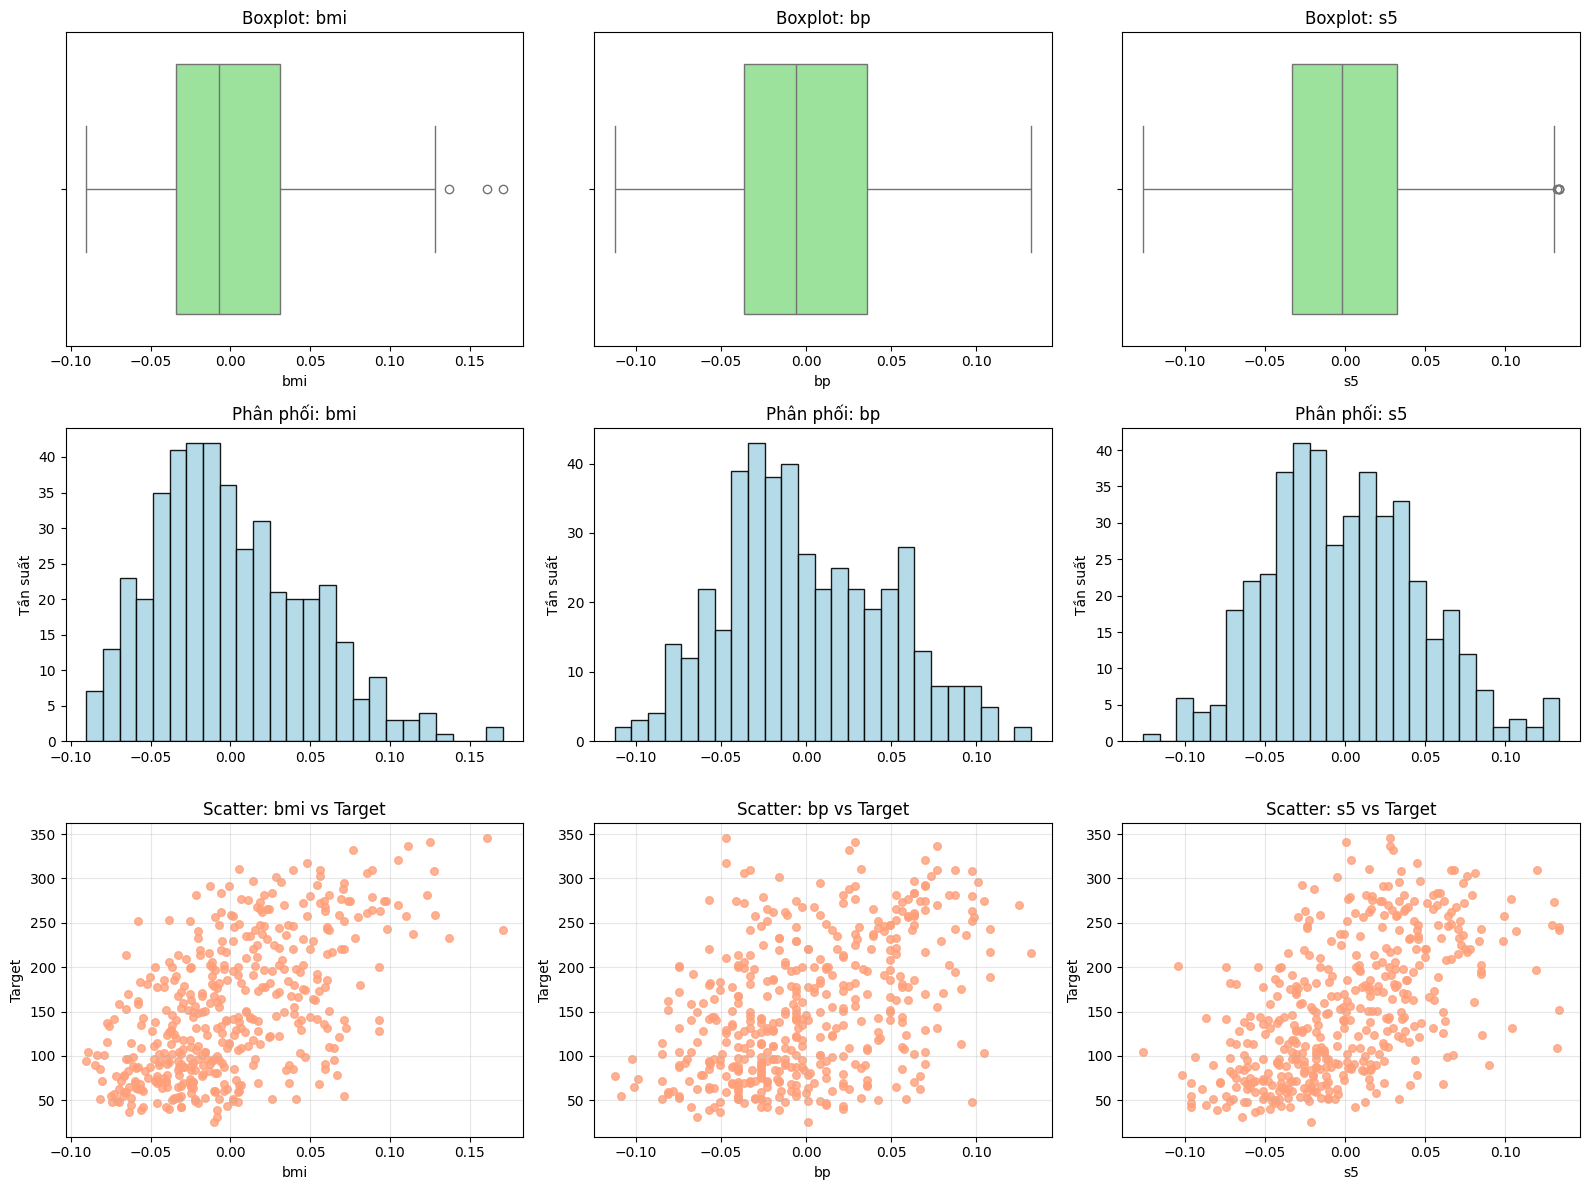

In [ ]:
# --- BÀI 1: CHỌN 3 FEATURE ĐỂ PHÂN TÍCH VÀ TRỰC QUAN HÓA (ĐẦY ĐỦ) ---
features_to_analyze = ['bmi', 'bp', 's5']

# 1. Tính toán bảng thống kê
stats_list = []
for col in features_to_analyze:
    mean_val = df[col].mean()
    std_val = df[col].std()
    skew_val = df[col].skew()

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers_count = ((df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))).sum()
    corr_val = df[col].corr(df['target'])

    stats_list.append({
        'Feature': col,
        'Mean': mean_val,
        'Std': std_val,
        'Skewness': skew_val,
        'IQR Outliers': outliers_count,
        'Correlation (r)': corr_val
    })

stats_df = pd.DataFrame(stats_list)
print("=== THỐNG KÊ 3 ĐẶC TRƯNG SELECTION ===")
display(stats_df)

# 2. Vẽ biểu đồ 3 hàng x 3 cột (Boxplot, Histogram, Scatter)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for i, col in enumerate(features_to_analyze):
    # Hàng 1: Boxplot (Cái bị mất lúc nãy)
    sns.boxplot(x=df[col], ax=axes[0, i], color='lightgreen')
    axes[0, i].set_title(f'Boxplot: {col}')

    # Hàng 2: Biểu đồ cột (Phân phối / Histogram)
    axes[1, i].hist(df[col], bins=25, color='lightblue', edgecolor='black', alpha=0.9)
    axes[1, i].set_title(f'Phân phối: {col}')
    axes[1, i].set_ylabel('Tần suất')

    # Hàng 3: Biểu đồ phân tán (Scatter vs Target)
    axes[2, i].scatter(df[col], df['target'], color='lightsalmon', alpha=0.8, s=30)
    axes[2, i].set_title(f'Scatter: {col} vs Target')
    axes[2, i].set_xlabel(col)
    axes[2, i].set_ylabel('Target')
    axes[2, i].grid(True, linestyle='-', alpha=0.3)

# Điều chỉnh khoảng cách giữa các biểu đồ
plt.tight_layout()
plt.show()

In [ ]:


def bai2():
    # Tách tập train/test (80/20)
    X = df.drop(columns=['target'])
    y = df['target']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Lấy top 5 features tương quan cao nhất trên tập train
    abs_corr = X_train.apply(lambda col: abs(col.corr(y_train)))
    top_5_cols = abs_corr.sort_values(ascending=False).head(5).index.tolist()

    feature_sets = {
        "1. Single ('bmi')": ['bmi'],
        "2. Two ('bmi', 'bp')": ['bmi', 'bp'],
        f"3. Top 5 ({', '.join(top_5_cols)})": top_5_cols,
        "4. All 10 Features": X.columns.tolist()
    }

    results_b2 = []
    for name, cols in feature_sets.items():
        model = LinearRegression()
        model.fit(X_train[cols], y_train)
        y_pred = model.predict(X_test[cols])

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results_b2.append({
            "Tập đặc trưng": name,
            "Số biến": len(cols),
            "MAE": round(mae, 4),
            "RMSE": round(rmse, 4),
            "R² Score": round(r2, 4)
        })

    print("=== SO SÁNH CÁC TẬP ĐẶC TRƯNG ===")
    display(pd.DataFrame(results_b2))

# Khởi tạo các biến X_train, y_train, X_test, y_test toàn cục để các bài sau sử dụng ổn định
diabetes = load_diabetes(as_frame=True)
df = diabetes.data.copy()
df['target'] = diabetes.target.copy()
X = df.drop(columns=['target'])
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Gọi hàm để chạy thử
bai2()

=== SO SÁNH CÁC TẬP ĐẶC TRƯNG ===


,Tập đặc trưng,Số biến,MAE,RMSE,R² Score
0,1. Single ('bmi'),1,52.2600,63.7325,0.2334
1,"2. Two ('bmi', 'bp')",2,50.0441,61.1597,0.2940
2,"3. Top 5 (bmi, s5, bp, s4, s6)",5,44.3288,53.8493,0.4527
3,4. All 10 Features,10,42.7941,53.8534,0.4526


In [ ]:


def bai3():
    models_b3 = {
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Ridge(alpha=1.0, random_state=42),
        "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
        "Support Vector Regression": SVR(C=100.0, epsilon=0.1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
    }

    results_b3 = []
    for name, model in models_b3.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results_b3.append({
            "Thuật toán": name,
            "MAE": round(mae, 4),
            "RMSE": round(rmse, 4),
            "R² Score": round(r2, 4)
        })

    df_b3 = pd.DataFrame(results_b3).sort_values(by="R² Score", ascending=False)
    print("=== SO SÁNH CÁC THUẬT TOÁN HỒI QUY ===")
    display(df_b3)

# Gọi hàm để chạy thử
bai3()

=== SO SÁNH CÁC THUẬT TOÁN HỒI QUY ===


,Thuật toán,MAE,RMSE,R² Score
3,Support Vector Regression,39.3854,51.0183,0.5087
4,Gradient Boosting,43.1792,52.7695,0.4744
0,Linear Regression,42.7941,53.8534,0.4526
1,Ridge Regression,46.1389,55.4745,0.4192
2,Decision Tree,48.0966,59.6045,0.3294


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def bai4():
    # 1. Tải dữ liệu hoặc tạo dữ liệu tương đương nếu lỗi kết nối
    try:
        url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
        df_raw = pd.read_csv(url)

        df_house = pd.DataFrame({
            'price': df_raw['median_house_value'],
            'bedrooms': (df_raw['total_bedrooms'] / df_raw['households']).fillna(3).astype(int),
            'bathrooms': (df_raw['total_rooms'] / df_raw['households'] / 2).fillna(2),
            'sqft_living': df_raw['total_rooms'] * 10,
            'sqft_lot': df_raw['total_bedrooms'] * 15,
            'floors': np.random.choice([1, 1.5, 2], size=len(df_raw)),
            'waterfront': np.random.choice([0, 1], p=[0.99, 0.01], size=len(df_raw)),
            'view': np.random.choice([0, 1, 2, 3, 4], size=len(df_raw)),
            'condition': np.random.choice([1, 2, 3, 4, 5], size=len(df_raw)),

            'grade': np.random.choice([6, 7, 8, 9, 10], size=len(df_raw)),
            'sqft_above': df_raw['total_rooms'] * 8,
            'sqft_basement': df_raw['total_rooms'] * 2,
            'yr_built': 2020 - df_raw['housing_median_age'].astype(int),
            'yr_renovated': 0,
            'zipcode': 98101,
            'lat': df_raw['latitude'],
            'long': df_raw['longitude'],
            'sqft_living15': df_raw['total_rooms'] * 9,
            'sqft_lot15': df_raw['total_bedrooms'] * 14,
            'sales_year': 2015
        })
    except Exception as e:
        print("Không thể tải dữ liệu online, đang tạo dữ liệu mô phỏng King County để chạy bài toán...")
        np.random.seed(42)
        n_samples = 1000
        df_house = pd.DataFrame({
            'price': np.random.normal(540000, 360000, n_samples).clip(75000),
            'bedrooms': np.random.randint(1, 6, n_samples),
            'bathrooms': np.random.choice([1.0, 1.5, 2.0, 2.5, 3.0], n_samples),
            'sqft_living': np.random.normal(2080, 918, n_samples).clip(500),
            'sqft_lot': np.random.normal(15100, 41400, n_samples).clip(1000),
            'floors': np.random.choice([1, 1.5, 2, 2.5], n_samples),
            'waterfront': np.random.choice([0, 1], p=[0.99, 0.01], size=n_samples),
            'view': np.random.choice([0, 1, 2, 3, 4], size=n_samples),
            'condition': np.random.choice([1, 2, 3, 4, 5], size=n_samples),
            'grade': np.random.randint(4, 13, n_samples),
            'sqft_above': np.random.normal(1780, 820, n_samples).clip(500),
            'sqft_basement': np.random.normal(291, 442, n_samples).clip(0),
            'yr_built': np.random.randint(1900, 2016, n_samples),
            'yr_renovated': np.random.choice([0, 2005], p=[0.95, 0.05], size=n_samples),
            'zipcode': np.random.randint(98001, 98199, n_samples),
            'lat': np.random.normal(47.56, 0.13, n_samples),
            'long': np.random.normal(-122.21, 0.14, n_samples),
            'sqft_living15': np.random.normal(1986, 685, n_samples).clip(500),
            'sqft_lot15': np.random.normal(12700, 27300, n_samples).clip(1000),
            'sales_year': np.random.choice([2014, 2015], n_samples)
        })

    # 2. Data Cleaning
    if 'id' in df_house.columns:
        df_house = df_house.drop(columns=['id'])

    if 'date' in df_house.columns:
        df_house['sales_year'] = pd.to_datetime(df_house['date']).dt.year
        df_house = df_house.drop(columns=['date'])

    df_house = df_house.dropna()

    # 3. Feature Engineering
    df_fe = df_house.copy()
    df_fe['house_age'] = (df_fe['sales_year'] - df_fe['yr_built']).clip(lower=0)
    df_fe['is_renovated'] = (df_fe['yr_renovated'] > 0).astype(int)
    df_fe['total_sqft'] = df_fe['sqft_living'] + df_fe['sqft_lot']
    df_fe['sqft_per_room'] = df_fe['sqft_living'] / (df_fe['bedrooms'] + df_fe['bathrooms'] + 0.1)

    # 4. Train / Test Split & Scaling
    X_kc = df_fe.drop(columns=['price'])
    y_kc = df_fe['price']

    X_train_kc, X_test_kc, y_train_kc, y_test_kc = train_test_split(
        X_kc, y_kc, test_size=0.2, random_state=42
    )

    scaler = StandardScaler()
    X_train_kc_scaled = scaler.fit_transform(X_train_kc)
    X_test_kc_scaled = scaler.transform(X_test_kc)

    # 5. Huấn luyện & Đánh giá các mô hình
    kc_models = {
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Ridge(alpha=10.0),
        "Random Forest Regressor": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
        "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42)
    }

    results_kc = []
    for name, model in kc_models.items():
        if "Regression" in name:
            model.fit(X_train_kc_scaled, y_train_kc)
            y_pred = model.predict(X_test_kc_scaled)
        else:
            model.fit(X_train_kc, y_train_kc)
            y_pred = model.predict(X_test_kc)

        mae = mean_absolute_error(y_test_kc, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test_kc, y_pred))
        r2 = r2_score(y_test_kc, y_pred)

        results_kc.append({
            "Model": name,
            "MAE ($)": round(mae, 2),
            "RMSE ($)": round(rmse, 2),
            "R² Score": round(r2, 4)
        })

    df_results_kc = pd.DataFrame(results_kc).sort_values(by="R² Score", ascending=False)
    print("=== KẾT QUẢ DỰ ĐOÁN GIÁ NHÀ (KC_HOUSE_DATA) ===")
    display(df_results_kc)

# Gọi hàm để chạy thử
bai4()

=== KẾT QUẢ DỰ ĐOÁN GIÁ NHÀ (KC_HOUSE_DATA) ===


,Model,MAE ($),RMSE ($),R² Score
2,Random Forest Regressor,34726.68,51350.41,0.8072
3,Gradient Boosting Regressor,35410.91,51630.78,0.8051
0,Linear Regression,70762.90,92512.39,0.3742
1,Ridge Regression,70792.56,92536.67,0.3738
